<a href="https://colab.research.google.com/github/ronjaladhikari213/AI-related-projects/blob/main/Mask_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("omkargurav/face-mask-dataset")

print("Path to dataset files:", path)

100%|██████████| 163M/163M [00:01<00:00, 124MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset,DataLoader
from PIL import Image
import matplotlib.image as mpimg
from torchvision.transforms import transforms
import pandas as pd
import os

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "CPU")
device

RuntimeError: Expected one of cpu, cuda, ipu, xpu, mkldnn, opengl, opencl, ideep, hip, ve, fpga, maia, xla, lazy, vulkan, mps, meta, hpu, mtia, privateuseone device type at start of device string: CPU

In [ ]:
import pandas as pd
file_path=[]
labels=[]
data_dir = os.path.join(path,"data")
mask_dir = os.path.join(data_dir,"with_mask")
without_mask_dir = os.path.join(data_dir,"without_mask")

for name in os.listdir(mask_dir):
  img_path1 = os.path.join(mask_dir,name)
  file_path.append(img_path1)

for name in os.listdir(without_mask_dir):
  img_path2 = os.path.join(without_mask_dir,name)
  file_path.append(img_path2)

for files in os.listdir(mask_dir):
  labels.append(1)

for files in os.listdir(without_mask_dir):
  labels.append(0)

df = pd.DataFrame(zip(file_path,labels),columns=["image_path","labels"])

df

,image_path,labels
0,/root/.cache/kagglehub/datasets/omkargurav/fac...,1
1,/root/.cache/kagglehub/datasets/omkargurav/fac...,1
2,/root/.cache/kagglehub/datasets/omkargurav/fac...,1
3,/root/.cache/kagglehub/datasets/omkargurav/fac...,1
4,/root/.cache/kagglehub/datasets/omkargurav/fac...,1
...,...,...
7548,/root/.cache/kagglehub/datasets/omkargurav/fac...,0
7549,/root/.cache/kagglehub/datasets/omkargurav/fac...,0
7550,/root/.cache/kagglehub/datasets/omkargurav/fac...,0
7551,/root/.cache/kagglehub/datasets/omkargurav/fac...,0


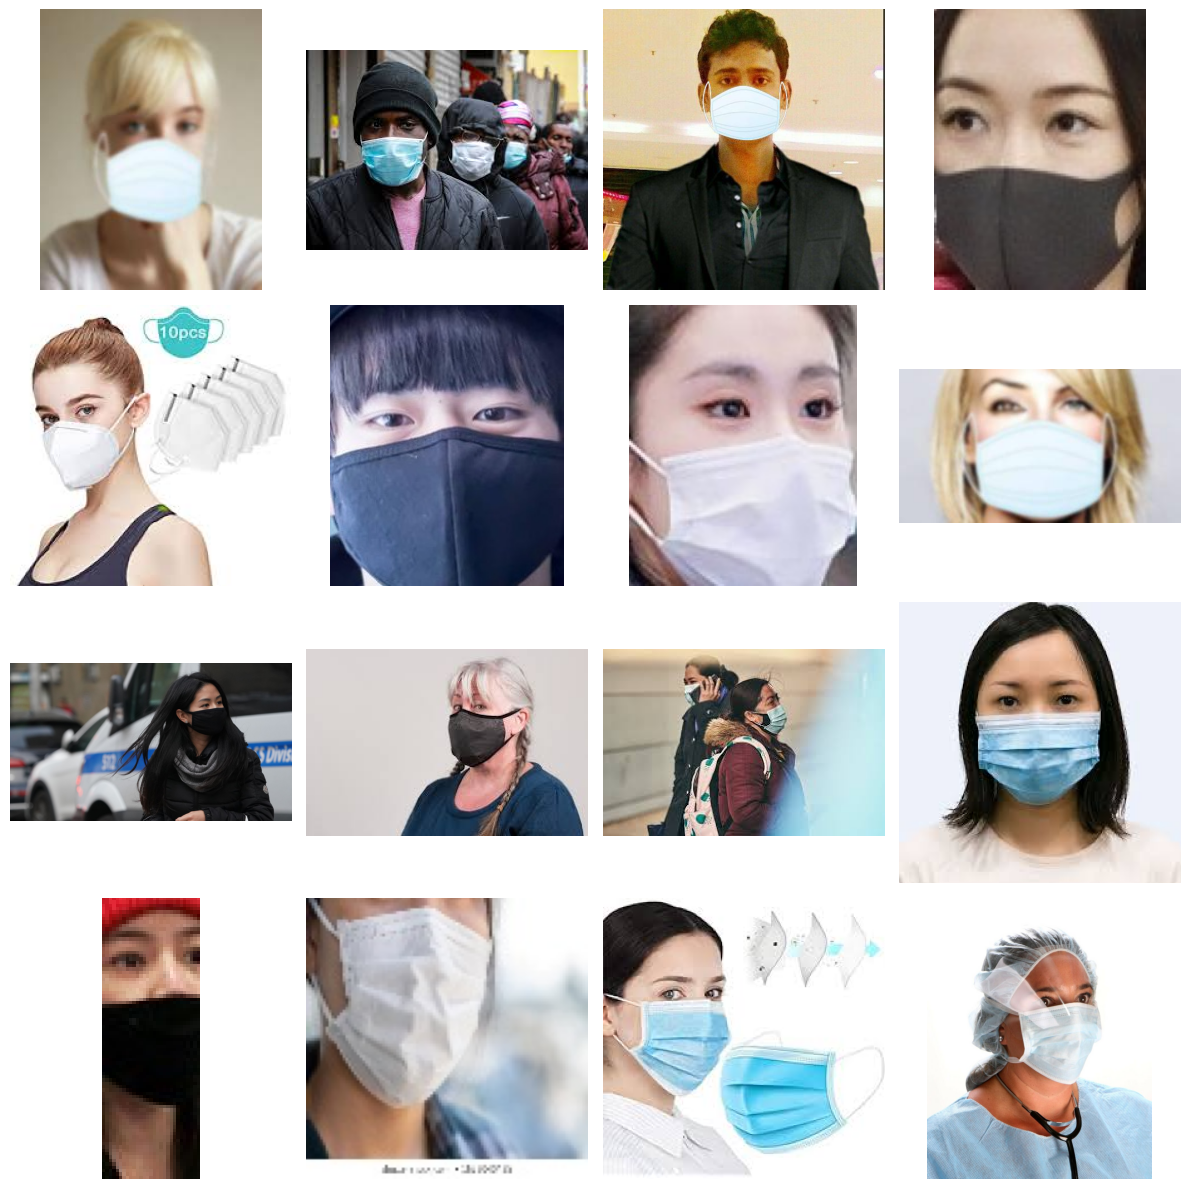

In [ ]:
images = []
for img in file_path[0:16]:
  image = mpimg.imread(img)
  images.append(image)

fig,axes = plt.subplots(4,4, figsize=(12,12))
for ax, img in zip(axes.flatten(), images):
    ax.imshow(img)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
torch.manual_seed(42)

In [ ]:
X = df.iloc[:,0]
y= df.iloc[:,1].astype(float)

X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=42,stratify=y_temp)

len(X_train)+len(X_val)+len(X_test)

y_train.value_counts(normalize=True)
y_val.value_counts(normalize=True)
y_test.value_counts(normalize=True)

overlap = set(X_train) & set(X_val)
print(len(overlap))

0


In [ ]:
custom_transform = transforms.Compose([
    transforms.Resize((96,96)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,0.5,0.5),std=(0.5,0.5,0.5))
])

eval_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3),
])

In [ ]:
class CustomDataset(Dataset):
  def __init__(self,features,labels,transform):
    self.features = features.tolist()

    self.labels = labels.tolist()
    self.transform = transform

  def __len__(self):
    return len(self.features)

  def __getitem__(self,idx):
    img_path = self.features[idx]
    label = self.labels[idx]
    image = Image.open(img_path).convert('RGB')

    image = self.transform(image)

    return image, torch.tensor(label,dtype=torch.long)

In [ ]:
train_dataset = CustomDataset(X_train,y_train,transform=custom_transform)
val_dataset = CustomDataset(X_val,y_val,transform=eval_transform)
test_dataset = CustomDataset(X_test,y_test,transform=eval_transform)

In [ ]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False,pin_memory=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False,pin_memory=True)

images, labels = next(iter(val_loader))
print(images.shape, images.dtype, labels.shape,labels.dtype,images.min(),images.max())

torch.Size([32, 3, 96, 96]) torch.float32 torch.Size([32]) torch.int64 tensor(-1.) tensor(1.)


In [ ]:
class MyNN(nn.Module):
  def __init__(self,input_features):
    super().__init__()

    self.features = nn.Sequential(
        nn.Conv2d(input_features,32,kernel_size=3,padding='same'),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2),

        nn.Conv2d(32,64,kernel_size = 3,padding='same'),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2),

        nn.Conv2d(64,128,kernel_size = 3,padding='same'),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2),

        nn.AdaptiveAvgPool2d(1)
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Dropout(p=0.3),
        nn.Linear(128,2)
    )
  def forward(self,x):
      x = self.features(x)
      x = self.classifier(x)

      return x

In [ ]:
lr = 0.01
epochs = 15

In [ ]:
model = MyNN(3)

model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=lr)

In [ ]:
from numpy import float32
for epoch in range(epochs):
  total_epoch_loss = 0
  best_val_acc=0
  for batch_features, batch_labels in train_loader:
    batch_features,batch_labels = batch_features.to(device),batch_labels.to(device)
    batch_labels = torch.tensor(batch_labels,dtype=torch.long)
    output = model(batch_features)

    loss = criterion(output,batch_labels)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    total_epoch_loss+=loss.item()
  avg_train_loss = total_epoch_loss/len(train_loader)
  model.eval()
  total_val_loss = 0
  correct = 0
  total = 0

  with torch.no_grad():
        for batch_features, batch_labels in val_loader:
            batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

            output = model(batch_features)
            loss = criterion(output, batch_labels)
            total_val_loss += loss.item()

            predicted = output.argmax(dim=1)
            total += batch_labels.size(0)
            correct += (predicted == batch_labels).sum().item()

  avg_val_loss = total_val_loss / len(val_loader)
  val_acc = correct / total

  print(f"Epoch {epoch+1} | train loss {avg_train_loss:.4f} | "
          f"val loss {avg_val_loss:.4f} | val acc {val_acc:.4f}")

  if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model1.pth")

/tmp/ipykernel_2690/590280605.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  batch_labels = torch.tensor(batch_labels,dtype=torch.long)


Epoch 1 | train loss 0.5391 | val loss 0.5170 | val acc 0.7670
Epoch 2 | train loss 0.4923 | val loss 0.5070 | val acc 0.7582
Epoch 3 | train loss 0.4676 | val loss 0.4918 | val acc 0.7855
Epoch 4 | train loss 0.3823 | val loss 0.4507 | val acc 0.7873
Epoch 5 | train loss 0.3096 | val loss 0.2757 | val acc 0.8959
Epoch 6 | train loss 0.2584 | val loss 0.3662 | val acc 0.8535
Epoch 7 | train loss 0.2463 | val loss 0.2712 | val acc 0.9082
Epoch 8 | train loss 0.2400 | val loss 0.2149 | val acc 0.9170
Epoch 9 | train loss 0.2173 | val loss 0.1933 | val acc 0.9197
Epoch 10 | train loss 0.1833 | val loss 0.1778 | val acc 0.9250
Epoch 11 | train loss 0.1546 | val loss 0.1634 | val acc 0.9400
Epoch 12 | train loss 0.1405 | val loss 0.1980 | val acc 0.9356
Epoch 13 | train loss 0.1525 | val loss 0.1441 | val acc 0.9444
Epoch 14 | train loss 0.1359 | val loss 0.1339 | val acc 0.9550
Epoch 15 | train loss 0.1283 | val loss 0.1704 | val acc 0.9382


In [ ]:
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.9576345984112974
